In [1]:
import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

# Load NLSY97 dataset
nlsy97 = pl.read_csv("data/raw/nlsy97/NLSY97_expanded.csv")

print("Dataset shape:", nlsy97.shape)
print("\nColumns:")
print(nlsy97.columns)


Dataset shape: (8984, 12)

Columns:
['R0000100', 'R0536300', 'R0536401', 'R0536402', 'R1204500', 'R1235800', 'R1302400', 'R1302500', 'R1482600', 'U5753300', 'U5753500', 'Z9061911']


In [2]:

# Preview the dataset
print(nlsy97.head(10))

# Check each column's data type and missing values
print("\nColumn information:")
print(nlsy97.schema)

# Summary statistics
print("\nSummary statistics:")
print(nlsy97.describe())


shape: (10, 12)
┌──────────┬──────────┬──────────┬──────────┬───┬──────────┬──────────┬──────────┬──────────┐
│ R0000100 ┆ R0536300 ┆ R0536401 ┆ R0536402 ┆ … ┆ R1482600 ┆ U5753300 ┆ U5753500 ┆ Z9061911 │
│ ---      ┆ ---      ┆ ---      ┆ ---      ┆   ┆ ---      ┆ ---      ┆ ---      ┆ ---      │
│ i64      ┆ i64      ┆ i64      ┆ i64      ┆   ┆ i64      ┆ i64      ┆ i64      ┆ i64      │
╞══════════╪══════════╪══════════╪══════════╪═══╪══════════╪══════════╪══════════╪══════════╡
│ 1        ┆ 2        ┆ 9        ┆ 1981     ┆ … ┆ 4        ┆ -5       ┆ -5       ┆ 0        │
│ 2        ┆ 1        ┆ 7        ┆ 1982     ┆ … ┆ 2        ┆ 1        ┆ 115000   ┆ 52       │
│ 3        ┆ 2        ┆ 9        ┆ 1983     ┆ … ┆ 2        ┆ 0        ┆ -4       ┆ 0        │
│ 4        ┆ 2        ┆ 2        ┆ 1981     ┆ … ┆ 2        ┆ 1        ┆ 45000    ┆ 52       │
│ 5        ┆ 1        ┆ 10       ┆ 1982     ┆ … ┆ 2        ┆ 1        ┆ 150000   ┆ 52       │
│ 6        ┆ 2        ┆ 1        ┆ 1982     

In [3]:

# Show all columns and their ranges
for col in nlsy97.columns:
    values = nlsy97[col]
    print(f"\n{col}")
    print("Minimum:", values.min())
    print("Maximum:", values.max())
    print("Negative values:", values.filter(values < 0).len())
    print("Unique values:", values.n_unique())



R0000100
Minimum: 1
Maximum: 9022
Negative values: 0
Unique values: 8984

R0536300
Minimum: 1
Maximum: 2
Negative values: 0
Unique values: 2

R0536401
Minimum: 1
Maximum: 12
Negative values: 0
Unique values: 12

R0536402
Minimum: 1980
Maximum: 1984
Negative values: 0
Unique values: 5

R1204500
Minimum: -48100
Maximum: 246474
Negative values: 2399
Unique values: 2244

R1235800
Minimum: 0
Maximum: 1
Negative values: 0
Unique values: 2

R1302400
Minimum: -4
Maximum: 95
Negative values: 1856
Unique values: 23

R1302500
Minimum: -4
Maximum: 95
Negative values: 688
Unique values: 23

R1482600
Minimum: 1
Maximum: 4
Negative values: 0
Unique values: 4

U5753300
Minimum: -5
Maximum: 1
Negative values: 2327
Unique values: 6

U5753500
Minimum: -5
Maximum: 380288
Negative values: 3783
Unique values: 426

Z9061911
Minimum: -4
Maximum: 52
Negative values: 1746
Unique values: 55


In [4]:

# Convert to pandas for statsmodels regression
df = nlsy97.to_pandas()

# Replace NLSY97 special missing-value codes
missing_codes = [-1, -2, -3, -4, -5]

for col in ["R1204500", "U5753500", "U5753300",
            "R1302400", "R1302500"]:
    df[col] = df[col].replace(missing_codes, np.nan)

# Education code 95 represents an unknown category
for col in ["R1302400", "R1302500"]:
    df[col] = df[col].replace(95, np.nan)

# Respondents who explicitly reported no job income
# are assigned zero wages when wages were skipped
no_income = df["U5753300"] == 0
df.loc[no_income & df["U5753500"].isna(), "U5753500"] = 0

# Keep respondents with valid childhood income
# and positive reported adult wages
analysis_df = df.loc[
    df["R1204500"].notna() &
    (df["U5753500"] > 0)
].copy()

# Create percentile ranks among the selected earners
analysis_df["parent_income_rank"] = (
    analysis_df["R1204500"].rank(pct=True) * 100
)

analysis_df["child_income_rank"] = (
    analysis_df["U5753500"].rank(pct=True) * 100
)

print("Total respondents:", len(df))
print("Respondents included in regression:", len(analysis_df))
print(analysis_df[
    ["parent_income_rank", "child_income_rank"]
].describe())


Total respondents: 8984
Respondents included in regression: 3847
       parent_income_rank  child_income_rank
count         3847.000000        3847.000000
mean            50.012997          50.012997
std             28.871017          28.865795
min              0.025994           0.025994
25%             25.110476          26.228230
50%             50.000000          49.571094
75%             74.980504          74.850533
max             99.064206          98.947232


In [5]:

# Simple linear regression
model1 = smf.ols(
    "child_income_rank ~ parent_income_rank",
    data=analysis_df
).fit()

# Display regression results
print(model1.summary())

# Extract important statistics
coefficient = model1.params["parent_income_rank"]
p_value = model1.pvalues["parent_income_rank"]
ci_lower, ci_upper = model1.conf_int().loc["parent_income_rank"]
r_squared = model1.rsquared

print("\n--- FINDING 1 RESULTS ---")
print(f"Coefficient: {coefficient:.4f}")
print(f"95% Confidence Interval: [{ci_lower:.4f}, {ci_upper:.4f}]")
print(f"P-value: {p_value:.6g}")
print(f"R-squared: {r_squared:.4f}")
print(f"Sample size: {int(model1.nobs)}")


                            OLS Regression Results                            
Dep. Variable:      child_income_rank   R-squared:                       0.087
Model:                            OLS   Adj. R-squared:                  0.086
Method:                 Least Squares   F-statistic:                     365.2
Date:                Sat, 14 Nov 2026   Prob (F-statistic):           7.73e-78
Time:                        18:17:09   Log-Likelihood:                -18220.
No. Observations:                3847   AIC:                         3.644e+04
Df Residuals:                    3845   BIC:                         3.646e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             35.2866      0

In [6]:

# Use parental education and demographics as controls.
# Here, mother's and father's education are treated as
# categorical variables.

adjusted_df = analysis_df.rename(columns={
    "R1302400": "father_education",
    "R1302500": "mother_education",
    "R0536300": "sex",
    "R1482600": "race_ethnicity"
}).copy()

# Remove observations missing any control variables
adjusted_df = adjusted_df.dropna(subset=[
    "parent_income_rank",
    "child_income_rank",
    "father_education",
    "mother_education",
    "sex",
    "race_ethnicity"
])

# Compare models on the SAME respondents
baseline_model = smf.ols(
    "child_income_rank ~ parent_income_rank",
    data=adjusted_df
).fit()

adjusted_model = smf.ols(
    """child_income_rank ~ parent_income_rank
       + C(father_education)
       + C(mother_education)
       + C(sex)
       + C(race_ethnicity)""",
    data=adjusted_df
).fit()

for name, model in [
    ("Baseline (same sample)", baseline_model),
    ("Adjusted", adjusted_model)
]:
    coef = model.params["parent_income_rank"]
    lower, upper = model.conf_int().loc["parent_income_rank"]

    print(f"\n{name}")
    print(f"Sample size: {int(model.nobs)}")
    print(f"Income coefficient: {coef:.4f}")
    print(f"95% CI: [{lower:.4f}, {upper:.4f}]")
    print(f"P-value: {model.pvalues['parent_income_rank']:.4g}")
    print(f"R-squared: {model.rsquared:.4f}")



Baseline (same sample)
Sample size: 3165
Income coefficient: 0.2809
95% CI: [0.2466, 0.3151]
P-value: 4.766e-56
R-squared: 0.0757

Adjusted
Sample size: 3165
Income coefficient: 0.1858
95% CI: [0.1462, 0.2254]
P-value: 6.92e-20
R-squared: 0.1570


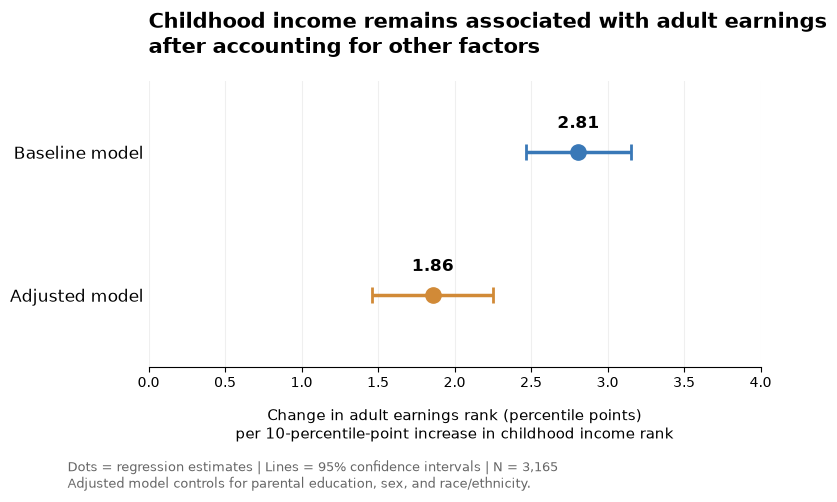

In [7]:

import matplotlib.pyplot as plt
from pathlib import Path

# Results from the two models using the same 3,165 respondents
models = ["Baseline model", "Adjusted model"]
coefficients = [0.2809 * 10, 0.1858 * 10]
ci_lower = [0.2466 * 10, 0.1462 * 10]
ci_upper = [0.3151 * 10, 0.2254 * 10]

# Calculate distances from the estimates to the CI bounds
errors = [
    [coef - lower for coef, lower in zip(coefficients, ci_lower)],
    [upper - coef for coef, upper in zip(coefficients, ci_upper)]
]

fig, ax = plt.subplots(figsize=(9, 5.5))

colors = ["#3978B7", "#D18A37"]
positions = [1, 0]

for i in range(2):
    ax.errorbar(
        coefficients[i],
        positions[i],
        xerr=[[errors[0][i]], [errors[1][i]]],
        fmt="o",
        color=colors[i],
        markersize=11,
        capsize=6,
        elinewidth=2.5,
        capthick=2,
        zorder=3
    )

    ax.text(
        coefficients[i],
        positions[i] + 0.17,
        f"{coefficients[i]:.2f}",
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

ax.set_yticks(positions)
ax.set_yticklabels(models, fontsize=12)

ax.set_xlim(0, 4)
ax.set_ylim(-0.5, 1.5)

ax.set_xlabel(
    "Change in adult earnings rank (percentile points)\n"
    "per 10-percentile-point increase in childhood income rank",
    fontsize=11,
    labelpad=12
)

ax.set_title(
    "Childhood income remains associated with adult earnings\n"
    "after accounting for other factors",
    fontsize=15,
    fontweight="bold",
    loc="left",
    pad=20
)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

ax.tick_params(axis="y", length=0)

fig.text(
    0.13, 0.04,
    "Dots = regression estimates | Lines = 95% confidence intervals | "
    "N = 3,165\n"
    "Adjusted model controls for parental education, sex, and race/ethnicity.",
    fontsize=9,
    color="#666666"
)

plt.subplots_adjust(left=0.22, bottom=0.26, top=0.78)

# Save figure to your project's figures folder
Path("figures").mkdir(exist_ok=True)
plt.savefig("figures/finding-one.png", dpi=300, bbox_inches="tight")

plt.show()
